# Análise exploratória dos fatores associados à evasão — Pré-defesa

**Tema:** Análise de fatores associados à evasão de estudantes do ensino superior utilizando técnicas de análise de dados e aprendizado de máquina — um estudo de caso no Inatel.

## Como conduzimos esta etapa

Antes de começarmos a procurar os fatores associados à evasão, entendemos que precisávamos conhecer melhor a base que foi construída para o trabalho. A ideia desta etapa não é chegar ainda a uma explicação definitiva para a evasão, mas entender quem está representado nos dados, como os estudantes aparecem ao longo dos semestres e quais características da trajetória acadêmica merecem ser investigadas com mais atenção.

Por isso, organizamos a exploração a partir de perguntas que foram surgindo tanto da literatura sobre permanência no ensino superior quanto das próprias características da base. Primeiro olhamos para a população e para o período analisado. Depois passamos pelos eventos de saída e, a partir daí, começamos a comparar as trajetórias acadêmicas, financeiras e socioeconômicas.

Essa sequência também nos ajuda a preparar a etapa seguinte. Antes de aplicar qualquer modelo de aprendizado de máquina, precisamos saber o que cada variável representa, quais informações estão disponíveis e quais limitações existem nos dados.

Um cuidado que mantemos durante toda a análise é não interpretar uma associação como causa. Os gráficos mostram padrões observados na base; eles não são, sozinhos, suficientes para afirmar que determinada característica provoca a evasão.


## 1. Antes de procurar os fatores, o que exatamente a nossa base representa?

Antes de começar a procurar fatores associados à evasão, primeiro precisamos entender a população que estamos analisando. Quantos estudantes aparecem na base? Quantos registros temos? Qual é o período coberto? E, principalmente, os dados permitem acompanhar o mesmo estudante em diferentes semestres?

Essas perguntas são importantes porque o nosso objetivo não é analisar uma fotografia de um único momento. Queremos observar a trajetória acadêmica e identificar o que aparece antes dos eventos de saída. Se a base não tivesse histórico suficiente por estudante, essa proposta não seria possível.

Essa primeira leitura se relaciona à etapa de entendimento dos dados do CRISP-DM. Também conversa com a perspectiva de Tinto, que trata a permanência e a saída como processos construídos ao longo da experiência do estudante no ensino superior, e não apenas como um acontecimento isolado.


In [1]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Ajuste de configuração para publicação; cálculo original preservado.
arquivo = os.environ.get("TCC_CSV_PATH", "dados_alunos.csv")

df = pd.read_csv(
    arquivo,
    sep=";",
    encoding="utf-8-sig",
    low_memory=False
)

# A extração ainda vem com a matrícula real do aluno (MATRICULA). Como o
# HANDLEALUNO já serve como identificador para juntar os registros de um
# mesmo estudante ao longo do tempo, a matrícula não é necessária para a
# análise e é descartada aqui, antes de qualquer outra coisa.
if "MATRICULA" in df.columns:
    df = df.drop(columns=["MATRICULA"])

print(f"Registros: {len(df):,}")
print(f"Alunos distintos: {df['HANDLEALUNO'].nunique():,}")
print(f"Semestres: {df['ANOSEMESTRE'].nunique():,}")
print(f"Primeiro semestre: {df['ANOSEMESTRE'].min()}")
print(f"Último semestre: {df['ANOSEMESTRE'].max()}")
print(f"Cursos: {df['SIGLACURSO'].nunique():,}")

Registros: 59,059
Alunos distintos: 7,615
Semestres: 35
Primeiro semestre: 2009/1
Último semestre: 2026/1
Cursos: 12


### O que encontramos

A base reúne **59.059 registros de 7.615 estudantes**, distribuídos em **35 semestres**, de **2009/1 a 2026/1**.

Esse resultado é importante para o nosso trabalho porque mostra que temos uma base longitudinal. O mesmo estudante pode aparecer em diferentes momentos da sua formação, permitindo observar mudanças de desempenho, frequência, progressão e vínculo ao longo do tempo.

Essa característica é fundamental para a pergunta que estamos fazendo. A partir dela, conseguimos olhar não apenas para quem saiu, mas também para o que estava acontecendo na trajetória desse estudante antes da saída.

Também retiramos a matrícula da análise e mantivemos o `HANDLEALUNO` como identificador interno para acompanhar os registros do mesmo estudante. Dessa forma, não precisamos trabalhar com um identificador pessoal que não acrescenta informação à análise.


## 2. Os estudantes aparecem em vários semestres?

Depois de conhecer o tamanho da base, a próxima pergunta foi mais específica: **cada estudante aparece em diferentes momentos ou temos muitos alunos com apenas um registro?**

Isso importa porque estamos tratando a evasão como parte de uma trajetória. Para investigar o que acontece antes de uma saída, precisamos ter registros anteriores ao evento. Por isso, calculamos quantos semestres diferentes conseguimos observar para cada estudante e representamos essa distribuição em um histograma.


count    7615.000000
mean        6.329613
std         4.640938
min         1.000000
25%         2.000000
50%         6.000000
75%        10.000000
max        27.000000
Name: ANOSEMESTRE, dtype: float64


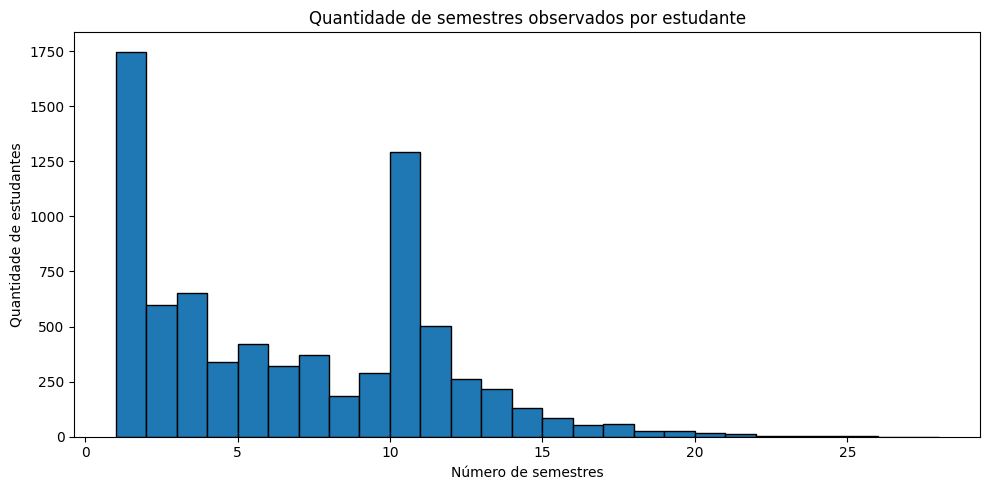

In [2]:
semestres_por_aluno = (
    df.groupby("HANDLEALUNO")["ANOSEMESTRE"]
      .nunique()
)

print(semestres_por_aluno.describe())

plt.figure(figsize=(10, 5))
plt.hist(
    semestres_por_aluno,
    bins=range(1, int(semestres_por_aluno.max()) + 2),
    edgecolor="black"
)
plt.title("Quantidade de semestres observados por estudante")
plt.xlabel("Número de semestres")
plt.ylabel("Quantidade de estudantes")
plt.tight_layout()
plt.show()

### O que essa análise nos ajuda a entender

O histograma mostra como o número de semestres observados varia entre os estudantes. Ele é importante porque confirma se a base realmente permite trabalhar com trajetória, mas também nos lembra de uma limitação: os estudantes entraram em anos diferentes e, portanto, não tiveram o mesmo tempo de exposição na base.

Por isso, não podemos interpretar simplesmente “mais registros” como “maior permanência”. Um aluno que ingressou em 2009 naturalmente pode ter muito mais semestres observados do que alguém que ingressou em 2025.

Essa diferença de tempo de observação será considerada nas análises seguintes.


## 3. Quem está representado na base? — distribuição por curso

Depois de verificar a dimensão temporal, quisemos entender como os estudantes estão distribuídos entre os cursos.

Essa pergunta surgiu porque a trajetória acadêmica não acontece exatamente nas mesmas condições em todos os cursos. O número de estudantes, a duração do curso e as características curriculares podem variar. Antes de comparar eventos de saída entre cursos, portanto, precisamos conhecer o tamanho de cada grupo.

Neste momento, não estamos tentando dizer que um curso tem mais ou menos evasão. O objetivo é apenas caracterizar a população que compõe a base e criar o contexto para as comparações que serão feitas depois.


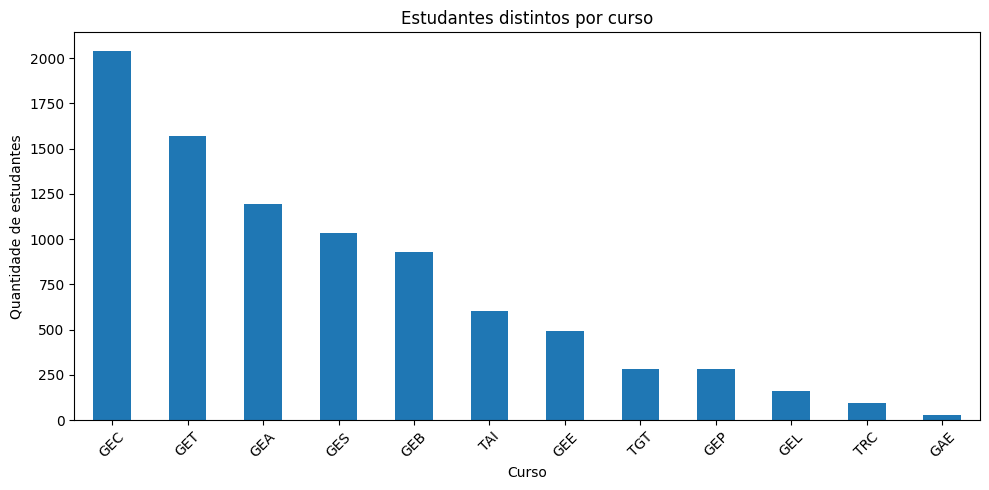

,estudantes
SIGLACURSO,
GEC,2041
GET,1570
GEA,1196
GES,1034
GEB,930
TAI,604
GEE,490
TGT,285
GEP,282


In [3]:
cursos = (
    df.groupby("SIGLACURSO")["HANDLEALUNO"]
      .nunique()
      .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
cursos.plot(kind="bar")
plt.title("Estudantes distintos por curso")
plt.xlabel("Curso")
plt.ylabel("Quantidade de estudantes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

cursos.to_frame("estudantes")

## 4. Quantos estudantes apresentam eventos de saída?

Depois de entender quem está na base, chegamos à pergunta central: **quantos estudantes apresentam algum evento institucional relacionado à saída?**

Para não transformar qualquer alteração de vínculo em evasão, definimos inicialmente como eventos principais: **desistência, abandono, cancelamento e desligamento**. Mantivemos transferência/afastamento separada porque esse registro, por si só, não permite concluir que o estudante abandonou a instituição ou o ensino superior.

Essa definição foi feita a partir dos próprios tipos de ocorrência disponíveis na base e da necessidade de separar situações com significados diferentes. Neste primeiro momento, portanto, usamos a expressão **evento de saída observado**. A definição final de evasão ainda será refinada a partir da análise da trajetória e dos status acadêmicos.


In [4]:
df = df.sort_values(["HANDLEALUNO", "ANOSEMESTRE"]).copy()

EVENTOS_SAIDA_PRINCIPAIS = [
    "TEVEDESISTENCIA",
    "TEVEABANDONO",
    "TEVECANCELAMENTO",
    "TEVEDESLIGAMENTO"
]

df["EVENTO_SAIDA"] = (
    df[EVENTOS_SAIDA_PRINCIPAIS].fillna(0).eq(1).any(axis=1)
).astype(int)

df["EVENTO_TRANS_AFASTAMENTO"] = (
    df["TEVETRANSAFASTAMENTO"].fillna(0).eq(1).astype(int)
    if "TEVETRANSAFASTAMENTO" in df.columns
    else 0
)

alunos_saida = (
    df.loc[df["EVENTO_SAIDA"] == 1, "HANDLEALUNO"]
      .dropna()
      .unique()
)

print(f"Estudantes com pelo menos um evento de saída principal: {len(alunos_saida):,}")
print(f"Ocorrências de saída principal: {df['EVENTO_SAIDA'].sum():,}")

if "TEVETRANSAFASTAMENTO" in df.columns:
    print(f"Estudantes com transferência/afastamento: {df.loc[df['EVENTO_TRANS_AFASTAMENTO']==1, 'HANDLEALUNO'].nunique():,}")

Estudantes com pelo menos um evento de saída principal: 3,507
Ocorrências de saída principal: 3,841
Estudantes com transferência/afastamento: 84


### Um cuidado importante na interpretação

O número encontrado aqui não deve ser apresentado simplesmente como “número de evadidos”.

O que conseguimos afirmar nesta etapa é quantos estudantes tiveram pelo menos um dos eventos que definimos como saída. Ainda precisamos verificar o que aconteceu depois desses eventos. Um estudante pode ter uma saída registrada e, posteriormente, retornar ou reingressar.

Essa verificação é importante porque a própria base mostrou que a trajetória de um estudante pode ter mais de um episódio. Por isso, antes da modelagem, precisamos transformar essa definição institucional em uma definição de evasão adequada ao objetivo do trabalho.


## 5. Como as saídas são registradas na instituição?

Depois de identificar a quantidade de estudantes com eventos de saída, fizemos uma pergunta mais específica: **quais tipos de saída aparecem na base e com que frequência?**

Essa análise é importante porque “saída” não é uma única situação. Desistência, abandono, cancelamento e desligamento são registrados separadamente pelo sistema acadêmico. Se juntássemos tudo imediatamente, perderíamos essa informação.

Olhar os eventos separadamente também nos ajuda a entender melhor o que estamos chamando de saída e a avaliar, mais adiante, se todos eles devem permanecer juntos na variável utilizada pelo modelo.


,Evento,Ocorrências
0,Desistência,2313
1,Abandono,761
2,Cancelamento,766
3,Desligamento,1


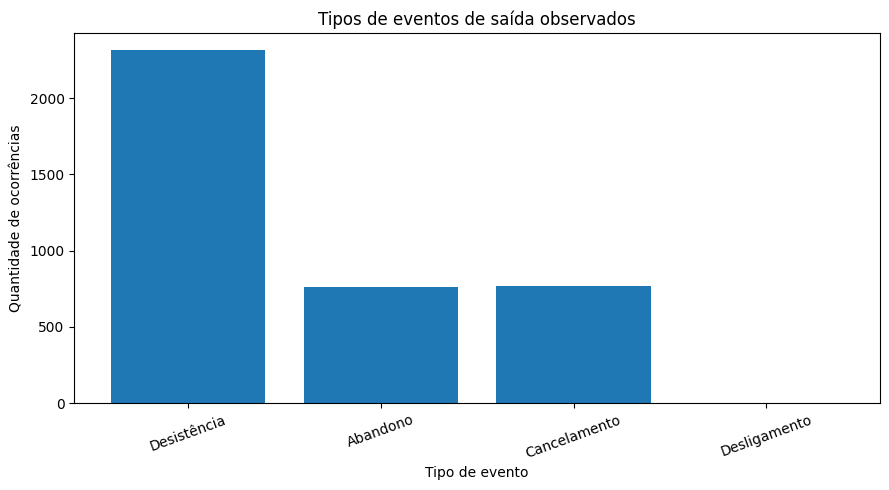

In [5]:
eventos = pd.DataFrame({
    "Evento": [
        "Desistência",
        "Abandono",
        "Cancelamento",
        "Desligamento"
    ],
    "Ocorrências": [
        df["TEVEDESISTENCIA"].sum(),
        df["TEVEABANDONO"].sum(),
        df["TEVECANCELAMENTO"].sum(),
        df["TEVEDESLIGAMENTO"].sum()
    ]
})

display(eventos)

plt.figure(figsize=(9, 5))
plt.bar(eventos["Evento"], eventos["Ocorrências"])
plt.title("Tipos de eventos de saída observados")
plt.xlabel("Tipo de evento")
plt.ylabel("Quantidade de ocorrências")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 6. Em que momentos da série histórica os eventos de saída aparecem?

Como nossa base cobre 35 semestres, também quisemos saber **como os eventos de saída se distribuem ao longo do tempo**.

Essa pergunta surgiu porque uma concentração em determinados semestres pode indicar que existe alguma característica temporal que merece ser investigada. Ao mesmo tempo, um pico pode estar relacionado a mudanças administrativas, alterações na forma de registro ou diferenças na cobertura da extração.

Por isso, o gráfico não será usado para dizer que determinado período “causou” mais evasão. Ele serve primeiro para enxergar o comportamento da série e identificar períodos que merecem uma investigação posterior.


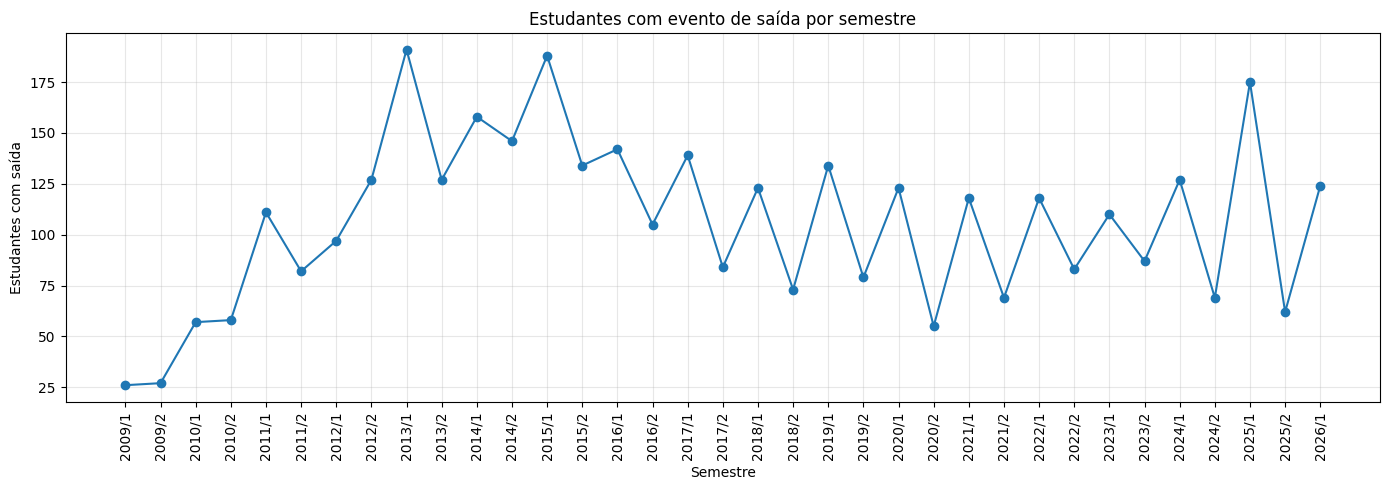

In [6]:
saidas_semestre = (
    df[df["EVENTO_SAIDA"] == 1]
      .groupby("ANOSEMESTRE")["HANDLEALUNO"]
      .nunique()
)

plt.figure(figsize=(14, 5))
plt.plot(saidas_semestre.index, saidas_semestre.values, marker="o")
plt.title("Estudantes com evento de saída por semestre")
plt.xlabel("Semestre")
plt.ylabel("Estudantes com saída")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. O comportamento dos eventos de saída é parecido entre os cursos?

Depois de conhecer a distribuição dos estudantes por curso, comparamos também a ocorrência de eventos de saída.

Aqui tivemos um cuidado importante: comparar somente a quantidade de estudantes que saíram favoreceria os cursos maiores. Por isso, além da quantidade, calculamos a proporção de estudantes de cada curso que apresentam pelo menos um evento de saída.

Mesmo assim, essa proporção ainda não deve ser chamada de taxa definitiva de evasão. Os cursos possuem tamanhos diferentes e os estudantes também possuem tempos diferentes de observação na base.

O objetivo desta análise é identificar diferenças que possam justificar uma investigação mais detalhada, e não estabelecer um ranking entre os cursos.


,estudantes,com_evento_saida,proporcao_com_evento_%
SIGLACURSO,,,
TRC,96,60,62.500000
TGT,285,173,60.701754
TAI,604,344,56.953642
GEB,930,450,48.387097
GEL,163,77,47.239264
GEP,282,116,41.134752
GEC,2041,834,40.862322
GET,1570,618,39.363057
GEE,490,189,38.571429


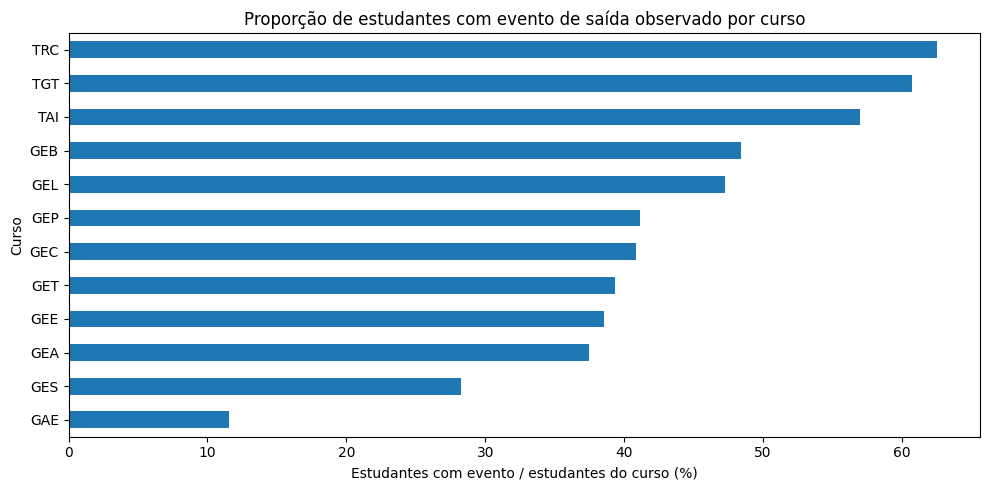

In [7]:
pop_curso = (
    df.groupby("SIGLACURSO")["HANDLEALUNO"]
      .nunique()
      .rename("estudantes")
)

saida_curso = (
    df[df["EVENTO_SAIDA"] == 1]
      .groupby("SIGLACURSO")["HANDLEALUNO"]
      .nunique()
      .rename("com_evento_saida")
)

curso_saida = pd.concat([pop_curso, saida_curso], axis=1).fillna(0)
curso_saida["proporcao_com_evento_%"] = (
    curso_saida["com_evento_saida"] / curso_saida["estudantes"] * 100
)

curso_saida = curso_saida.sort_values("proporcao_com_evento_%", ascending=False)

display(curso_saida)

plt.figure(figsize=(10, 5))
curso_saida["proporcao_com_evento_%"].sort_values().plot(kind="barh")
plt.title("Proporção de estudantes com evento de saída observado por curso")
plt.xlabel("Estudantes com evento / estudantes do curso (%)")
plt.ylabel("Curso")
plt.tight_layout()
plt.show()

### Como estamos interpretando essa comparação

Se encontrarmos diferenças entre os cursos, vamos tratá-las como um ponto de investigação, e não como uma conclusão sobre qual curso tem “mais evasão”.

Uma forma mais adequada de explicar o resultado é dizer que **a proporção de estudantes com eventos de saída varia entre os cursos** e que essa diferença precisa ser interpretada considerando o tamanho das populações e o tempo de observação de cada estudante.

Esse cuidado é importante para não transformar uma análise descritiva em uma conclusão que os dados ainda não sustentam.


## 8. A composição por sexo é diferente entre os grupos?

Também decidimos observar o sexo porque é uma característica demográfica disponível na base e pode ajudar a descrever a composição dos estudantes que apresentam ou não eventos de saída.

A pergunta aqui é simples: **a proporção de estudantes com evento de saída é semelhante entre os grupos de sexo observados na base?**

Não estamos partindo da ideia de que sexo determina evasão. A análise serve para verificar se existe uma diferença descritiva que justifique atenção nas etapas seguintes. Além do gráfico, incluímos um teste qui-quadrado para verificar se a diferença observada na tabela de contingência é compatível com uma associação estatística, em vez de depender apenas da impressão visual do gráfico.


,populacao,com_saida,proporcao_com_saida_%
SEXO,,,
F,1678,698,41.597139
M,5928,2806,47.334683


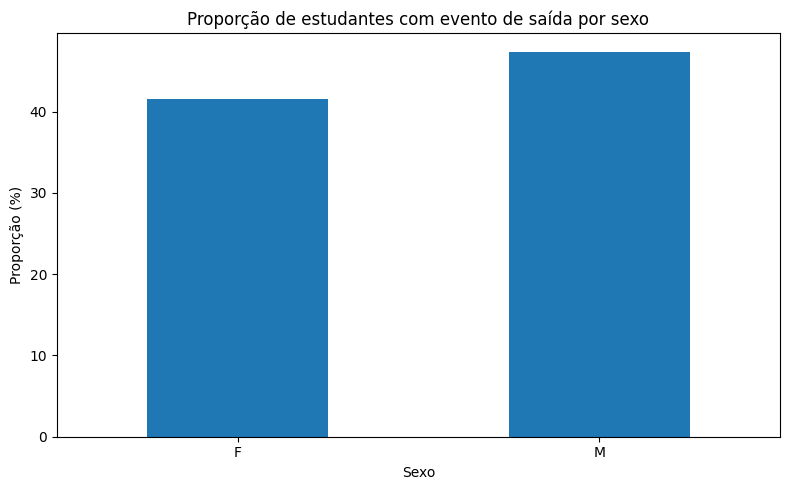

qui-quadrado = 17.10 | p-valor = 0.0000


In [8]:
sexo_pop = (
    df.groupby("SEXO")["HANDLEALUNO"]
      .nunique()
      .rename("populacao")
)

sexo_saida = (
    df[df["EVENTO_SAIDA"] == 1]
      .groupby("SEXO")["HANDLEALUNO"]
      .nunique()
      .rename("com_saida")
)

sexo = pd.concat([sexo_pop, sexo_saida], axis=1).fillna(0)
sexo["proporcao_com_saida_%"] = sexo["com_saida"] / sexo["populacao"] * 100

display(sexo)

plt.figure(figsize=(8, 5))
sexo["proporcao_com_saida_%"].plot(kind="bar")
plt.title("Proporção de estudantes com evento de saída por sexo")
plt.xlabel("Sexo")
plt.ylabel("Proporção (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Teste qui-quadrado: a diferença de proporção entre os sexos é
# estatisticamente significativa, ou pode ser só ruído amostral?
from scipy.stats import chi2_contingency

dedup = df.drop_duplicates("HANDLEALUNO")
tabela_contingencia = pd.crosstab(
    dedup["SEXO"],
    dedup["HANDLEALUNO"].isin(alunos_saida)
)
chi2, p_valor, gl, esperado = chi2_contingency(tabela_contingencia)
print(f"qui-quadrado = {chi2:.2f} | p-valor = {p_valor:.4f}")

### E o turno?

O turno entrou na análise porque ele representa uma característica concreta da rotina acadêmica. Estudar em horários diferentes pode estar relacionado a diferentes condições de organização da vida do estudante, como trabalho e outras atividades.

Não estamos assumindo que o turno explica a saída. A pergunta é se encontramos diferenças na proporção de estudantes com eventos de saída entre os turnos e se essa variável merece continuar na investigação.

Como acontece com as demais variáveis, o resultado aqui é descritivo e será interpretado junto das outras dimensões da trajetória.


,populacao,com_saida,proporcao_com_saida_%
TURNO,,,
Integral,5774,2405,41.652234
Noturno,2666,1164,43.660915


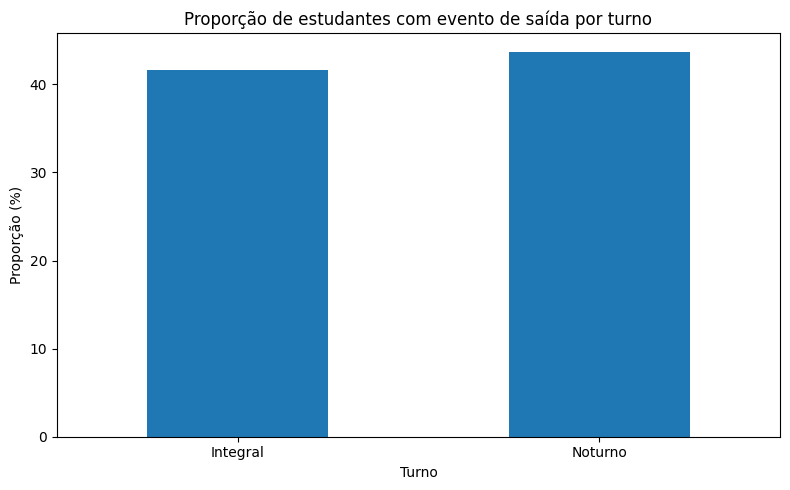

In [9]:
turno_pop = (
    df.groupby("TURNO")["HANDLEALUNO"]
      .nunique()
      .rename("populacao")
)

turno_saida = (
    df[df["EVENTO_SAIDA"] == 1]
      .groupby("TURNO")["HANDLEALUNO"]
      .nunique()
      .rename("com_saida")
)

turno = pd.concat([turno_pop, turno_saida], axis=1).fillna(0)
turno["proporcao_com_saida_%"] = turno["com_saida"] / turno["populacao"] * 100

display(turno)

plt.figure(figsize=(8, 5))
turno["proporcao_com_saida_%"].plot(kind="bar")
plt.title("Proporção de estudantes com evento de saída por turno")
plt.xlabel("Turno")
plt.ylabel("Proporção (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. O desempenho acadêmico muda antes da saída?

A partir daqui começamos a entrar nas variáveis que estão mais diretamente relacionadas à trajetória acadêmica.

Uma das primeiras perguntas foi: **o desempenho observado imediatamente antes de um evento de saída é diferente do observado entre estudantes que não apresentam saída?**

Essa escolha não foi aleatória. A literatura sobre permanência no ensino superior, especialmente a perspectiva de Tinto, dá importância à experiência acadêmica e ao desempenho dentro da trajetória do estudante. Além disso, trabalhos de mineração de dados educacionais sobre evasão utilizam indicadores acadêmicos para procurar padrões relacionados à saída.

Para evitar usar uma informação que já possa ter sido afetada pelo próprio evento de saída, usamos o **semestre imediatamente anterior à primeira saída observada**.


In [10]:
registros_pre_saida = []

for aluno, grupo in df[df["HANDLEALUNO"].isin(alunos_saida)].groupby("HANDLEALUNO"):
    grupo = grupo.sort_values("ANOSEMESTRE").reset_index(drop=True)

    indices_saida = grupo.index[grupo["EVENTO_SAIDA"] == 1]

    if len(indices_saida) == 0:
        continue

    primeira_saida = indices_saida[0]

    if primeira_saida == 0:
        continue

    registros_pre_saida.append(grupo.iloc[primeira_saida - 1].copy())

df_pre_saida = pd.DataFrame(registros_pre_saida)

print(f"Estudantes com pelo menos um semestre observável antes da primeira saída: {len(df_pre_saida):,}")

Estudantes com pelo menos um semestre observável antes da primeira saída: 1,896


### Como montamos o grupo de comparação?

Para comparar o desempenho, precisávamos definir também um momento de referência para quem não apresenta evento de saída.

Usamos o **último registro disponível do estudante sem saída observada**. Isso permite trabalhar com uma observação por estudante em cada grupo, em vez de dar pesos diferentes a alunos que aparecem em quantidades diferentes de semestres.

Ainda existe uma diferença importante entre os grupos: um estudante sem saída pode simplesmente continuar matriculado no último período observado, enquanto outro estudante já teve tempo suficiente para apresentar um evento de saída. Por isso, tratamos essa comparação como uma primeira análise exploratória e não como uma comparação causal.


In [11]:
alunos_sem_saida = np.setdiff1d(
    df["HANDLEALUNO"].dropna().unique(),
    alunos_saida
)

df_sem_saida = (
    df[df["HANDLEALUNO"].isin(alunos_sem_saida)]
      .sort_values(["HANDLEALUNO", "ANOSEMESTRE"])
      .groupby("HANDLEALUNO")
      .tail(1)
      .copy()
)

print(f"Estudantes sem evento de saída observado: {len(alunos_sem_saida):,}")

Estudantes sem evento de saída observado: 4,108


### A definição de saída está coerente com o status acadêmico?

Antes de avançar, fizemos uma verificação que consideramos importante: **os estudantes que o nosso indicador considera “sem saída” estão realmente ativos no sistema acadêmico?**

Essa pergunta surgiu porque os quatro eventos utilizados na variável `EVENTO_SAIDA` são ocorrências específicas. Pode existir um estudante com status “Inativo” sem que um desses quatro flags esteja marcado.

Se isso acontecer, significa que os eventos sozinhos não descrevem toda a situação acadêmica do estudante. Por isso cruzamos o grupo sem saída com `STATUSALUNO`.


In [12]:
status_grupo_sem_saida = df_sem_saida["STATUSALUNO"].value_counts(dropna=False)
display(status_grupo_sem_saida)

inativos_sem_evento = df_sem_saida[df_sem_saida["STATUSALUNO"] == "Inativo"]
print(
    f"Estudantes marcados como 'Inativo' no Benner, mas sem nenhum dos "
    f"quatro eventos de saída: {len(inativos_sem_evento):,}"
)

STATUSALUNO
Ativo                      3692
Inativo                     314
Desconhecido                 63
Matrícula Pendente           28
Em Mobilidade Acadêmica      11
Name: count, dtype: int64

Estudantes marcados como 'Inativo' no Benner, mas sem nenhum dos quatro eventos de saída: 314


### O que encontramos

Encontramos **314 estudantes classificados como “Inativo” no Benner que não apresentavam nenhum dos quatro eventos de saída utilizados na definição inicial**.

Para nós, esse foi um resultado importante da análise exploratória, porque mostrou uma limitação concreta da variável-alvo que estávamos construindo. Não podemos simplesmente assumir que os quatro flags representam todos os casos de saída.

A partir desse resultado, ficou claro que a definição final da variável-alvo precisa ser revisada, combinando os eventos registrados com o histórico de `STATUSALUNO` e com a trajetória posterior do estudante. Essa revisão será feita antes da modelagem.


## 10. Preparação das variáveis numéricas

Antes de comparar as variáveis acadêmicas e financeiras, verificamos como elas foram armazenadas na extração.

Algumas colunas vieram com vírgula decimal ou foram interpretadas como texto pelo pandas. Fazer qualquer média, mediana ou gráfico diretamente sobre essas colunas poderia gerar resultados incorretos.

Por isso, criamos uma conversão específica para as variáveis numéricas. Mantivemos fora dessa transformação as variáveis que representam categorias, como escolaridade dos pais e faixa de patrimônio.

Essa etapa parece simples, mas é importante porque uma análise exploratória só é útil se os valores estiverem no formato correto.


In [13]:
def para_numero(serie):
    return pd.to_numeric(
        serie.astype("string")
             .str.replace(",", ".", regex=False)
             .replace(["", "nan", "None", "<NA>"], pd.NA),
        errors="coerce"
    )

variaveis_numericas = [
    "CRENOSEMESTRE",
    "VALORMENSALIDADE",
    "IA04_01",
    "IA04_02",
    "IA10_01",
    "IA12_01",
    "IA34_03",
    "IA65_03",
    "IA70_01",
    "IA70_03",
    "IA70_05",
    "IA75_01",
    "IA75_02",
    "IA75_03",
    "IA75_04",
    "IA75_05"
]

for col in variaveis_numericas:
    if col in df.columns:
        df[col + "_NUM"] = para_numero(df[col])

for base in [df_pre_saida, df_sem_saida]:
    for col in variaveis_numericas:
        if col in base.columns:
            base[col + "_NUM"] = para_numero(base[col])

## 11. O CRE apresenta um comportamento diferente antes da saída?

Depois de preparar as variáveis, começamos pelo CRE porque ele resume uma parte importante do desempenho acadêmico do estudante.

A pergunta foi: **a distribuição do CRE no semestre anterior à primeira saída é diferente da distribuição observada no grupo sem saída?**

O gráfico de caixa foi escolhido porque permite comparar mediana, dispersão e valores extremos dos dois grupos. Como o objetivo nesta etapa é procurar sinais na trajetória, não estamos tentando afirmar que um determinado valor de CRE provoca a saída.


In [14]:
print("CRE — semestre anterior à primeira saída")
display(df_pre_saida["CRENOSEMESTRE_NUM"].describe())

print("\nCRE — último registro dos estudantes sem saída observada")
display(df_sem_saida["CRENOSEMESTRE_NUM"].describe())

plt.figure(figsize=(9, 5))
plt.boxplot(
    [
        df_sem_saida["CRENOSEMESTRE_NUM"].dropna(),
        df_pre_saida["CRENOSEMESTRE_NUM"].dropna()
    ],
    tick_labels=[
        "Sem saída observada",
        "Semestre anterior à saída"
    ]
)
plt.title("Distribuição do CRE")
plt.ylabel("CRE (%)")
plt.tight_layout()
plt.show()

CRE — semestre anterior à primeira saída


count       1166.0
mean     24.014563
std      22.109285
min            0.0
25%           3.57
50%          20.22
75%          36.94
max           99.0
Name: CRENOSEMESTRE_NUM, dtype: Float64


CRE — último registro dos estudantes sem saída observada


count       3712.0
mean     69.648753
std      21.571348
min            0.0
25%           64.0
50%          75.07
75%         83.505
max          100.0
Name: CRENOSEMESTRE_NUM, dtype: Float64

### O que encontramos no CRE

Na comparação entre os grupos, encontramos uma diferença grande no desempenho acadêmico. No semestre anterior à primeira saída, o CRE médio foi de 24,01, com mediana de 20,22. Entre os estudantes sem saída observada, o CRE médio no último registro foi de 69,65, com mediana de 75,07.

A diferença chamou nossa atenção porque é grande e aparece justamente no período imediatamente anterior ao evento de saída. Isso não significa que encontramos uma causa da evasão. O que o resultado nos mostra é que existe um **padrão acadêmico bastante evidente** que merece ser aprofundado com outras variáveis de desempenho.

Esse resultado também ajudou a orientar as próximas perguntas: se o CRE apresenta uma diferença tão grande, será que aprovação, reprovação e frequência apresentam comportamento semelhante?


## 12. O CRE sozinho conta toda a história?

Depois de encontrar uma diferença importante no CRE, quisemos entender se ela também aparece em indicadores mais específicos do semestre.

Por isso analisamos **percentual de aprovação e percentual de reprovação**. A ideia foi separar melhor os componentes do desempenho: em vez de olhar somente para uma medida agregada, verificar se o estudante que apresenta uma saída também chega a esse momento com maior reprovação ou menor aprovação.

Essa comparação ajuda a verificar se o sinal encontrado no CRE é isolado ou se aparece em diferentes medidas da trajetória acadêmica.


In [15]:
comparacao_desempenho = pd.DataFrame({
    "Aprovação — saída": df_pre_saida["IA75_03_NUM"].describe(),
    "Aprovação — sem saída": df_sem_saida["IA75_03_NUM"].describe(),
    "Reprovação — saída": df_pre_saida["IA34_03_NUM"].describe(),
    "Reprovação — sem saída": df_sem_saida["IA34_03_NUM"].describe()
})

display(comparacao_desempenho)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].boxplot(
    [
        df_sem_saida["IA75_03_NUM"].dropna(),
        df_pre_saida["IA75_03_NUM"].dropna()
    ],
    tick_labels=["Sem saída", "Antes da saída"]
)
axes[0].set_title("Percentual de aprovação")
axes[0].set_ylabel("%")

axes[1].boxplot(
    [
        df_sem_saida["IA34_03_NUM"].dropna(),
        df_pre_saida["IA34_03_NUM"].dropna()
    ],
    tick_labels=["Sem saída", "Antes da saída"]
)
axes[1].set_title("Percentual de reprovação")
axes[1].set_ylabel("%")

plt.tight_layout()
plt.show()

,Aprovação — saída,Aprovação — sem saída,Reprovação — saída,Reprovação — sem saída
count,1896.0,4108.0,1896.0,4108.0
mean,1.659283,10.089094,2.31962,0.487585
std,4.586771,15.510024,2.4437,1.257688
min,0.0,0.0,0.0,0.0
25%,0.0,3.0,0.0,0.0
50%,0.0,5.0,2.0,0.0
75%,2.0,8.0,4.0,0.0
max,74.0,88.0,13.0,10.0


## 13. A frequência também apresenta diferença antes da saída?

Desempenho acadêmico não envolve apenas notas e aprovação. A frequência é outra dimensão da experiência do estudante e, por isso, decidimos analisar o percentual de frequência registrado no semestre.

A pergunta foi: **os estudantes que apresentam uma saída chegam a esse momento com uma frequência diferente daquela observada no grupo sem saída?**

O indicador utilizado é o `IA04_01`, calculado a partir da carga horária e das faltas. A comparação nos ajuda a verificar se existe também um sinal relacionado à participação nas atividades acadêmicas.


In [16]:
print("Frequência — antes da saída")
display(df_pre_saida["IA04_01_NUM"].describe())

print("\nFrequência — sem saída observada")
display(df_sem_saida["IA04_01_NUM"].describe())

plt.figure(figsize=(9, 5))
plt.boxplot(
    [
        df_sem_saida["IA04_01_NUM"].dropna(),
        df_pre_saida["IA04_01_NUM"].dropna()
    ],
    tick_labels=["Sem saída", "Antes da saída"]
)
plt.title("Percentual de frequência")
plt.ylabel("Frequência (%)")
plt.tight_layout()
plt.show()

Frequência — antes da saída


count       1350.0
mean     67.617422
std      32.702939
min            0.0
25%          55.33
50%          81.94
75%         90.585
max          100.0
Name: IA04_01_NUM, dtype: Float64


Frequência — sem saída observada


count       3803.0
mean     90.708099
std       17.42019
min            0.0
25%          90.56
50%           95.0
75%          97.82
max          100.0
Name: IA04_01_NUM, dtype: Float64

### E as faltas estão concentradas em algumas disciplinas?

O percentual geral de frequência pode esconder situações diferentes. Um estudante pode ter uma frequência razoável no conjunto das disciplinas e, ao mesmo tempo, ter ultrapassado o limite de faltas em algumas matérias.

Por isso também olhamos o `IA04_02`, que indica a quantidade de disciplinas com mais de 25% de faltas.

A pergunta aqui é: **antes da saída, encontramos mais estudantes com faltas concentradas em disciplinas específicas?**

Esse indicador complementa a frequência geral e nos ajuda a enxergar a trajetória com um pouco mais de detalhe.


In [17]:
print("Estudantes com pelo menos uma disciplina acima de 25% de faltas:")
print(
    "Antes da saída:",
    (df_pre_saida["IA04_02_NUM"] > 0).sum()
)
print(
    "Sem saída:",
    (df_sem_saida["IA04_02_NUM"] > 0).sum()
)

Estudantes com pelo menos uma disciplina acima de 25% de faltas:
Antes da saída: 503
Sem saída: 183


## 14. O trancamento aparece antes das saídas?

Trancamento não foi colocado como sinônimo de evasão. Ele representa uma interrupção formal da trajetória e pode ser seguido de retorno.

Mesmo assim, decidimos investigar: **estudantes que posteriormente apresentam eventos de saída possuem mais frequentemente histórico de trancamento?**

Essa pergunta surgiu da própria natureza longitudinal da base. Um trancamento pode fazer parte de uma trajetória que termina em saída, mas também pode representar apenas uma pausa temporária. Por isso, o resultado será usado como indicador de trajetória, e não como definição do desfecho.


,Grupo,Percentual com histórico de trancamento
0,Com saída observada,19.931565
1,Sem saída observada,6.256086


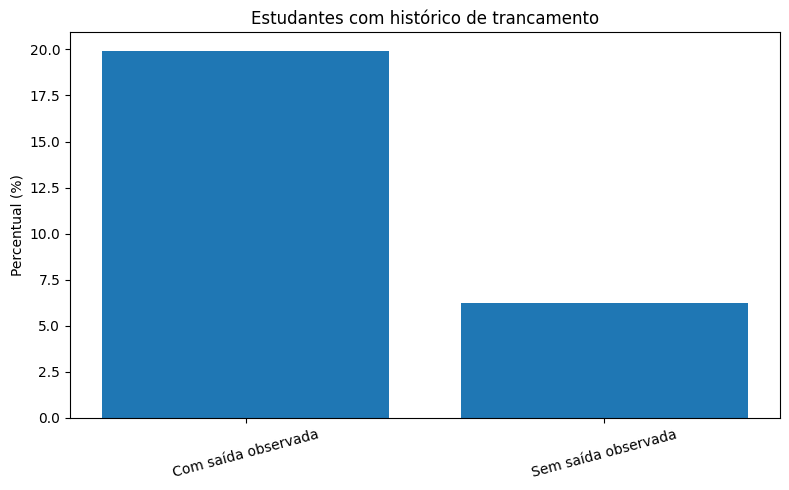

In [18]:
trancamento_por_aluno = (
    df.groupby("HANDLEALUNO")["TEVETRANCAMENTO"]
      .max()
      .fillna(0)
)

grupo_saida_tranc = trancamento_por_aluno[
    trancamento_por_aluno.index.isin(alunos_saida)
]

grupo_sem_saida_tranc = trancamento_por_aluno[
    trancamento_por_aluno.index.isin(alunos_sem_saida)
]

res_trancamento = pd.DataFrame({
    "Grupo": ["Com saída observada", "Sem saída observada"],
    "Percentual com histórico de trancamento": [
        (grupo_saida_tranc == 1).mean() * 100,
        (grupo_sem_saida_tranc == 1).mean() * 100
    ]
})

display(res_trancamento)

plt.figure(figsize=(8, 5))
plt.bar(
    res_trancamento["Grupo"],
    res_trancamento["Percentual com histórico de trancamento"]
)
plt.title("Estudantes com histórico de trancamento")
plt.ylabel("Percentual (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 15. Existe uma dimensão financeira associada às trajetórias de saída?

Depois das variáveis acadêmicas, passamos para uma dimensão diferente: a financeira.

Essa escolha também tem base na literatura sobre permanência. A trajetória do estudante não depende apenas do desempenho dentro da instituição; condições externas e financeiras podem interferir na permanência.

Nossa base permite observar algumas dessas condições por meio de bolsa institucional, FIES e perda de FIES. Assim, a pergunta foi: **esses indicadores aparecem de maneira diferente entre estudantes com e sem eventos de saída?**

Aqui também não queremos atribuir causalidade. O objetivo é verificar se existe um padrão financeiro que justifique uma investigação conjunta com as demais variáveis.


,Grupo,Com bolsa (%),Com FIES (%),Perdeu FIES (%)
0,Com saída observada,97.428289,4.049045,1.539778
1,Sem saída observada,94.626064,8.519961,2.020448


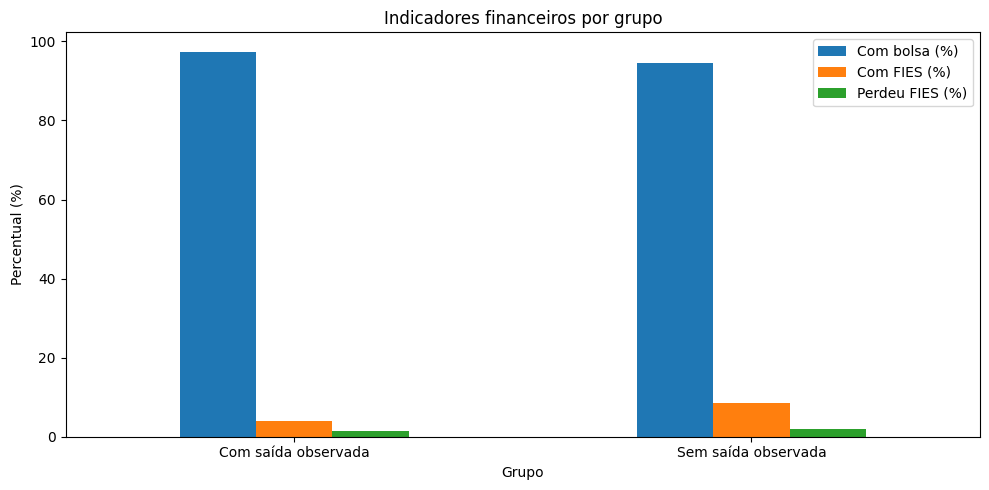

In [19]:
# Bolsa: considera se o estudante teve algum percentual de bolsa > 0
bolsa_por_aluno = (
    df.groupby("HANDLEALUNO")["IA10_01_NUM"]
      .max()
)

# FIES (IA12) e perda de FIES (IA13) já vêm como 0/1 na extração
fies_por_aluno = (
    df.groupby("HANDLEALUNO")["IA12"]
      .apply(lambda s: s.eq(1).any())
)

perda_fies_por_aluno = (
    df.groupby("HANDLEALUNO")["IA13"]
      .apply(lambda s: s.eq(1).any())
)

financeiro = pd.DataFrame({
    "Grupo": ["Com saída observada", "Sem saída observada"],
    "Com bolsa (%)": [
        (bolsa_por_aluno.loc[bolsa_por_aluno.index.isin(alunos_saida)] > 0).mean() * 100,
        (bolsa_por_aluno.loc[bolsa_por_aluno.index.isin(alunos_sem_saida)] > 0).mean() * 100
    ],
    "Com FIES (%)": [
        fies_por_aluno.loc[fies_por_aluno.index.isin(alunos_saida)].mean() * 100,
        fies_por_aluno.loc[fies_por_aluno.index.isin(alunos_sem_saida)].mean() * 100
    ],
    "Perdeu FIES (%)": [
        perda_fies_por_aluno.loc[perda_fies_por_aluno.index.isin(alunos_saida)].mean() * 100,
        perda_fies_por_aluno.loc[perda_fies_por_aluno.index.isin(alunos_sem_saida)].mean() * 100
    ]
})

display(financeiro)

financeiro.set_index("Grupo").plot(kind="bar", figsize=(10, 5))
plt.title("Indicadores financeiros por grupo")
plt.ylabel("Percentual (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 16. O contexto socioeconômico apresenta diferenças entre os grupos?

A próxima pergunta foi mais ampla: **existem diferenças no contexto socioeconômico dos estudantes que apresentam eventos de saída?**

A base possui informações sobre renda do estudante, renda dos pais, patrimônio familiar e escolaridade dos pais. Essas variáveis ajudam a complementar a análise acadêmica, porque permitem observar características do contexto em que a trajetória acontece.

Não esperamos que uma única variável socioeconômica explique a saída. O objetivo é identificar possíveis diferenças e, ao mesmo tempo, verificar a qualidade dessas informações. Valores ausentes e categorias pouco preenchidas precisam ser considerados antes de qualquer modelagem.


In [20]:
socio_numericas = [
    "IA70_01_NUM",  # renda da mãe
    "IA70_03_NUM",  # renda do estudante
    "IA70_05_NUM"   # renda do pai
]

display(df[socio_numericas].describe().T)

# Os valores de renda têm outliers bem extremos (o máximo passa de R$ 1 milhão,
# enquanto a mediana fica na casa dos R$ 1.200). Em escala linear o boxplot
# fica ilegível, então a comparação usa escala logarítmica só para
# visualização — as estatísticas descritivas acima continuam na escala original.
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, col in zip(axes, socio_numericas):
    dados_sem_saida = df_sem_saida[col].dropna()
    dados_pre_saida = df_pre_saida[col].dropna()

    ax.boxplot(
        [
            dados_sem_saida[dados_sem_saida > 0],
            dados_pre_saida[dados_pre_saida > 0]
        ],
        tick_labels=["Sem saída", "Antes da saída"]
    )
    ax.set_yscale("log")
    ax.set_title(col.replace("_NUM", ""))
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

,count,mean,std,min,25%,50%,75%,max
IA70_01_NUM,15190.0,4009.277735,38682.816747,0.0,0.0,1200.0,2529.1675,1836025.0
IA70_03_NUM,15190.0,1149.233088,9214.035266,0.0,0.0,0.0,1100.0,309800.0
IA70_05_NUM,15190.0,4017.480672,32400.591753,0.0,0.0,1412.0,3122.28,1720000.0


### Como analisamos o patrimônio familiar

O `IA70_04` não representa um valor numérico contínuo. Ele vem como faixa de patrimônio declarada pelo estudante.

Por isso, não faria sentido calcular uma média como se cada categoria fosse um número. Optamos por comparar a distribuição percentual das categorias entre os dois grupos.

A pergunta continua sendo a mesma: **a composição das faixas de patrimônio é diferente entre quem apresenta e quem não apresenta evento de saída?**


,Sem saída (%),Antes da saída (%)
IA70_04,,
Não Informado,7.180695,26.536313
"Até R$ 10.000,00",5.885815,7.541899
"R$ 10.000,01 a R$ 30.000,00",3.178340,4.189944
"R$ 30.000,01 a R$ 60.000,00",35.903473,28.770950
"R$ 60.000,01 a R$ 150.000,01",20.600353,12.011173
"Acima de R$ 150.000,01",27.251324,20.949721


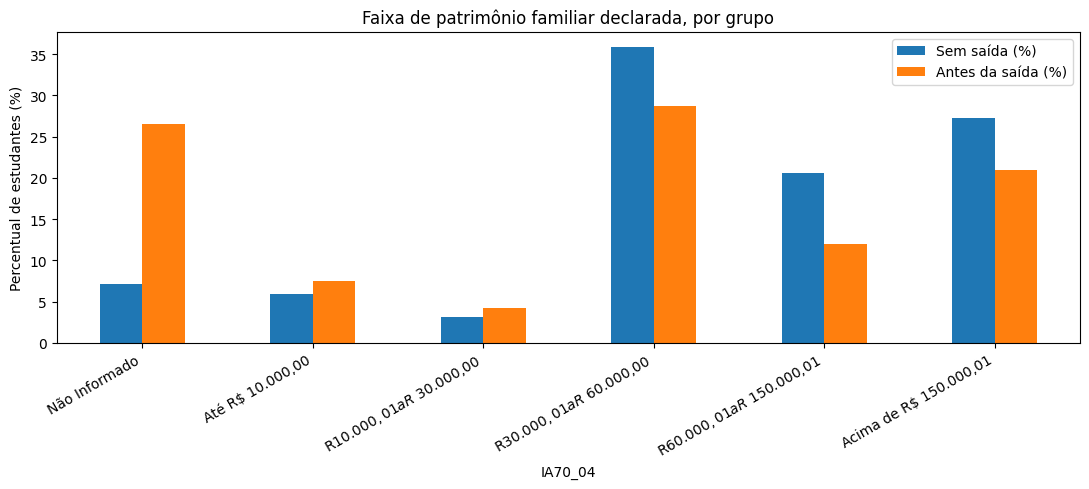

In [21]:
ordem_patrimonio = [
    "Não Informado",
    "Até R$ 10.000,00",
    "R$ 10.000,01 a R$ 30.000,00",
    "R$ 30.000,01 a R$ 60.000,00",
    "R$ 60.000,01 a R$ 150.000,01",
    "Acima de R$ 150.000,01"
]

patrimonio_grupo = pd.DataFrame({
    "Sem saída (%)": df_sem_saida["IA70_04"].value_counts(normalize=True).mul(100),
    "Antes da saída (%)": df_pre_saida["IA70_04"].value_counts(normalize=True).mul(100)
}).reindex(ordem_patrimonio)

display(patrimonio_grupo)

patrimonio_grupo.plot(kind="bar", figsize=(11, 5))
plt.title("Faixa de patrimônio familiar declarada, por grupo")
plt.ylabel("Percentual de estudantes (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### E a escolaridade dos pais?

A escolaridade da mãe e do pai foi analisada da mesma maneira: como variável categórica.

Essa informação entrou porque representa uma dimensão do contexto familiar que pode complementar as variáveis financeiras. Mais uma vez, não estamos tratando escolaridade dos pais como causa da evasão. Estamos verificando se a composição dos grupos apresenta alguma diferença que mereça ser considerada na análise conjunta.


,Sem saída (%),Antes da saída (%)
IA70_02,,
Não Informado,13.125368,20.111732
Sem Escolaridade,1.883461,2.513966
Ensino Fundamental,16.597999,15.363128
Ensino Médio,29.899941,26.256983
Curso Técnico,3.296057,4.748603
Ensino Superior,25.073573,21.229050
Pós-Graduação,9.770453,8.938547
Mestrado,0.294291,0.837989
Doutorado,0.058858,NaN


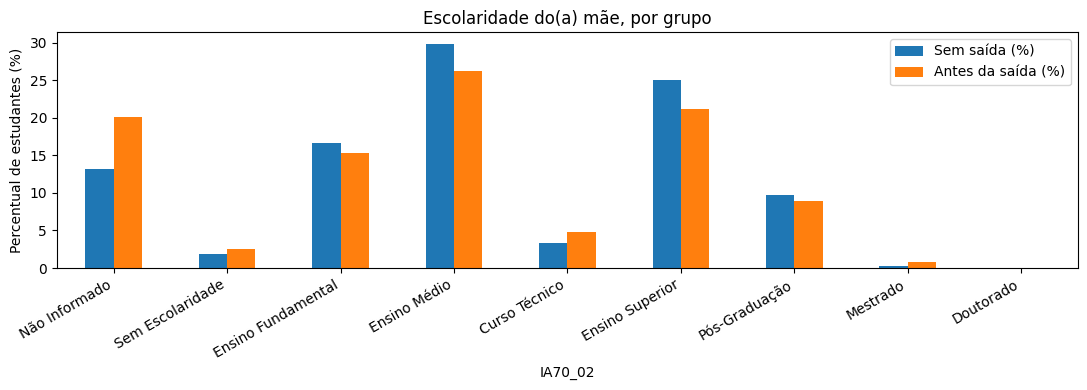

,Sem saída (%),Antes da saída (%)
IA70_06,,
Não Informado,34.432019,41.899441
Sem Escolaridade,2.118893,2.793296
Ensino Fundamental,17.951736,13.966480
Ensino Médio,23.778693,19.273743
Curso Técnico,4.590936,6.145251
Ensino Superior,12.301354,12.569832
Pós-Graduação,4.002354,2.793296
Mestrado,0.647440,0.558659
Doutorado,0.176574,NaN


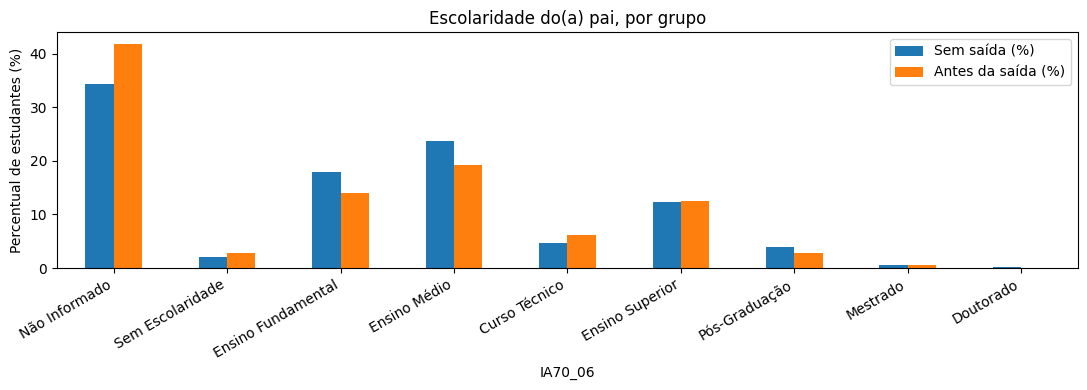

In [22]:
ordem_escolaridade = [
    "Não Informado",
    "Sem Escolaridade",
    "Ensino Fundamental",
    "Ensino Médio",
    "Curso Técnico",
    "Ensino Superior",
    "Pós-Graduação",
    "Mestrado",
    "Doutorado"
]

for coluna, titulo in [("IA70_02", "mãe"), ("IA70_06", "pai")]:
    escolaridade_grupo = pd.DataFrame({
        "Sem saída (%)": df_sem_saida[coluna].value_counts(normalize=True).mul(100),
        "Antes da saída (%)": df_pre_saida[coluna].value_counts(normalize=True).mul(100)
    }).reindex(ordem_escolaridade)

    display(escolaridade_grupo)

    escolaridade_grupo.plot(kind="bar", figsize=(11, 4))
    plt.title(f"Escolaridade do(a) {titulo}, por grupo")
    plt.ylabel("Percentual de estudantes (%)")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

## 17. A saída acontece em diferentes momentos da trajetória?

Até aqui olhamos principalmente para o semestre anterior à saída. Mas surgiu uma pergunta complementar: **em que momento da trajetória os estudantes estão quando ocorre o primeiro evento de saída?**

Essa questão é importante porque o risco de saída pode não ser distribuído de maneira uniforme ao longo da formação. A literatura sobre permanência discute a trajetória do estudante e as mudanças que acontecem ao longo do curso; por isso, decidimos verificar como esse comportamento aparece especificamente nos dados do Inatel.

Não estamos importando uma taxa ou um padrão de outra instituição. Primeiro observamos a nossa própria série histórica e deixamos que os dados mostrem como os eventos estão distribuídos.


count    3507.000000
mean        2.546621
std         4.167388
min         0.000000
25%         0.000000
50%         1.000000
75%         3.000000
max        29.000000
Name: SEMESTRES_ANTES_DA_PRIMEIRA_SAIDA, dtype: float64

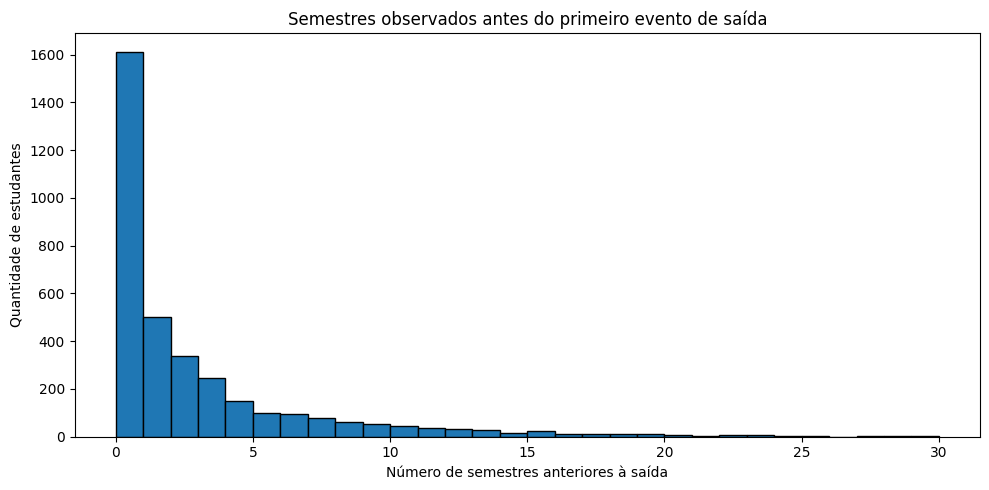

In [23]:
# Número de registros/semestres observados antes da primeira saída
tempo_ate_saida = []

for aluno, grupo in df[df["HANDLEALUNO"].isin(alunos_saida)].groupby("HANDLEALUNO"):
    grupo = grupo.sort_values("ANOSEMESTRE").reset_index(drop=True)

    idx = grupo.index[grupo["EVENTO_SAIDA"] == 1]

    if len(idx) == 0:
        continue

    primeira_saida = idx[0]

    tempo_ate_saida.append({
        "HANDLEALUNO": aluno,
        "SEMESTRES_ANTES_DA_PRIMEIRA_SAIDA": primeira_saida
    })

df_tempo_saida = pd.DataFrame(tempo_ate_saida)

display(df_tempo_saida["SEMESTRES_ANTES_DA_PRIMEIRA_SAIDA"].describe())

plt.figure(figsize=(10, 5))
plt.hist(
    df_tempo_saida["SEMESTRES_ANTES_DA_PRIMEIRA_SAIDA"],
    bins=range(
        0,
        int(df_tempo_saida["SEMESTRES_ANTES_DA_PRIMEIRA_SAIDA"].max()) + 2
    ),
    edgecolor="black"
)
plt.title("Semestres observados antes do primeiro evento de saída")
plt.xlabel("Número de semestres anteriores à saída")
plt.ylabel("Quantidade de estudantes")
plt.tight_layout()
plt.show()

## 18. Depois de uma saída, o estudante retorna?

Essa foi uma das perguntas que mais afetou a forma como pensamos a variável-alvo.

Ao encontrar um evento de saída, não podemos assumir automaticamente que aquele estudante deixou definitivamente a instituição. A base possui informação de reingresso e também permite acompanhar o estudante em semestres posteriores.

Por isso perguntamos: **quantos estudantes apresentam um reingresso formal depois de uma saída observada?**

O resultado dessa análise será usado para separar “evento de saída” de “saída definitiva” e evitar que trajetórias diferentes sejam tratadas como se fossem iguais.


REINGRESSOU_DEPOIS
0    3439
1      68
Name: count, dtype: int64


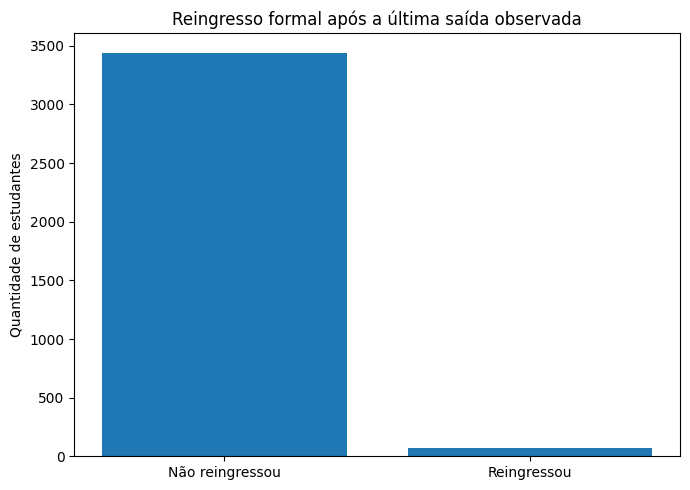

In [24]:
resultados = []

for aluno, grupo in df[df["HANDLEALUNO"].isin(alunos_saida)].groupby("HANDLEALUNO"):

    grupo = grupo.sort_values("ANOSEMESTRE")

    semestres_saida = grupo.loc[
        grupo["EVENTO_SAIDA"] == 1,
        "ANOSEMESTRE"
    ]

    if len(semestres_saida) == 0:
        continue

    ultima_saida = semestres_saida.max()

    reingressou_depois = (
        (grupo["ANOSEMESTRE"] > ultima_saida) &
        (grupo["TEVEREINGRESSO"] == 1)
    ).any()

    resultados.append({
        "HANDLEALUNO": aluno,
        "ULTIMA_SAIDA": ultima_saida,
        "REINGRESSOU_DEPOIS": int(reingressou_depois)
    })

df_resultado = pd.DataFrame(resultados)

print(df_resultado["REINGRESSOU_DEPOIS"].value_counts())

contagem_reingresso = (
    df_resultado["REINGRESSOU_DEPOIS"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

plt.figure(figsize=(7, 5))
plt.bar(
    ["Não reingressou", "Reingressou"],
    contagem_reingresso.values
)
plt.title("Reingresso formal após a última saída observada")
plt.ylabel("Quantidade de estudantes")
plt.tight_layout()
plt.show()

## 19. Alguns estudantes apresentam mais de um evento de saída?

Também verificamos se um mesmo estudante pode apresentar mais de um evento de saída ao longo da trajetória.

Essa pergunta surgiu naturalmente depois da análise de reingresso. Se existem estudantes que saem, retornam e depois apresentam uma nova saída, uma classificação simples de “evadiu” ou “não evadiu” deixa de representar toda a trajetória.

Por isso, antes de definir definitivamente a variável-alvo, precisamos entender quantos episódios de saída aparecem por estudante e como eles se relacionam com os registros posteriores.


Estudantes com mais de um evento de saída: 236


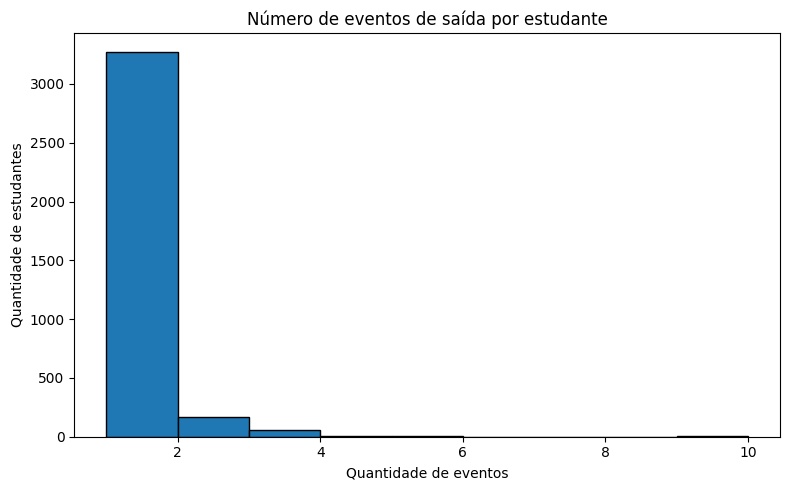

In [25]:
quantidade_saidas = (
    df.groupby("HANDLEALUNO")["EVENTO_SAIDA"]
      .sum()
)

multiplas_saidas = quantidade_saidas[quantidade_saidas > 1]

print(f"Estudantes com mais de um evento de saída: {len(multiplas_saidas):,}")

plt.figure(figsize=(8, 5))
plt.hist(
    quantidade_saidas[quantidade_saidas > 0],
    bins=range(
        1,
        int(quantidade_saidas.max()) + 2
    ),
    edgecolor="black"
)
plt.title("Número de eventos de saída por estudante")
plt.xlabel("Quantidade de eventos")
plt.ylabel("Quantidade de estudantes")
plt.tight_layout()
plt.show()

## 20. A queda no CRE começa antes do semestre da saída?

A diferença encontrada no CRE do semestre anterior chamou nossa atenção, mas ainda faltava responder uma questão: **essa diferença aparece somente no último semestre ou já existe uma mudança nos semestres anteriores?**

Como estamos trabalhando com uma base longitudinal, decidimos olhar os três semestres anteriores à primeira saída, quando há informação disponível.

Essa análise ajuda a distinguir duas situações: um desempenho baixo concentrado imediatamente antes da saída ou uma trajetória de queda que já vinha acontecendo. Em ambos os casos, estamos observando associação e evolução temporal, e não tentando provar uma relação de causa.


,count,median,mean
DISTANCIA_SAIDA,,,
-3,806,34.435,35.095968
-2,1058,29.655,31.802552
-1,1166,20.22,24.014563


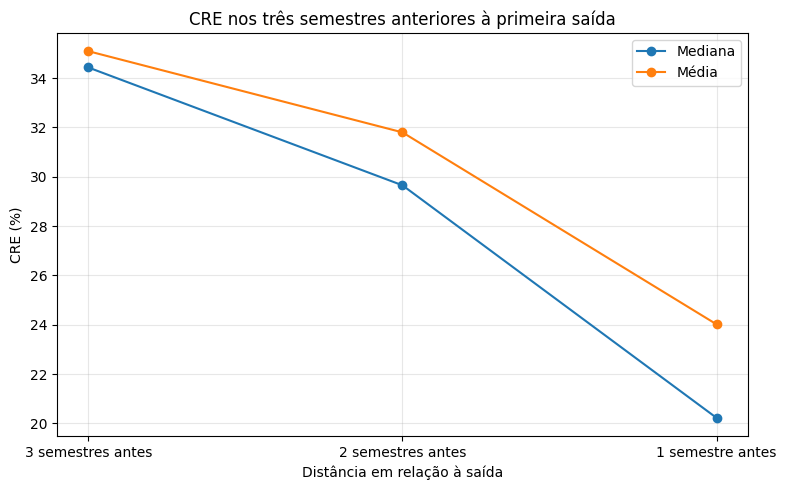

In [26]:
trajetorias = []

for aluno, grupo in df[df["HANDLEALUNO"].isin(alunos_saida)].groupby("HANDLEALUNO"):

    grupo = grupo.sort_values("ANOSEMESTRE").reset_index(drop=True)

    idx_saida = grupo.index[grupo["EVENTO_SAIDA"] == 1]

    if len(idx_saida) == 0:
        continue

    p = idx_saida[0]

    for distancia in [3, 2, 1]:
        pos = p - distancia

        if pos >= 0:
            trajetorias.append({
                "HANDLEALUNO": aluno,
                "DISTANCIA_SAIDA": -distancia,
                "CRE": grupo.loc[pos, "CRENOSEMESTRE_NUM"]
            })

df_traj_cre = pd.DataFrame(trajetorias)

traj_cre = (
    df_traj_cre.groupby("DISTANCIA_SAIDA")["CRE"]
    .agg(["count", "median", "mean"])
)

display(traj_cre)

plt.figure(figsize=(8, 5))
plt.plot(
    traj_cre.index,
    traj_cre["median"],
    marker="o",
    label="Mediana"
)
plt.plot(
    traj_cre.index,
    traj_cre["mean"],
    marker="o",
    label="Média"
)
plt.title("CRE nos três semestres anteriores à primeira saída")
plt.xlabel("Distância em relação à saída")
plt.ylabel("CRE (%)")
plt.xticks([-3, -2, -1], ["3 semestres antes", "2 semestres antes", "1 semestre antes"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 21. Antes de modelar, o que ainda precisamos saber sobre a qualidade dos dados?

Depois de explorar as principais dimensões da trajetória, voltamos para a qualidade da base.

Essa etapa é importante porque encontramos variáveis com diferentes níveis de preenchimento, categorias “Desconhecido” e informações que não estão disponíveis para todos os estudantes. Se ignorarmos isso, podemos criar comparações enviesadas ou alimentar o modelo com informações que não são comparáveis.

Por isso levantamos o percentual de valores ausentes e identificamos as variáveis com maior falta de informação. Essa análise vai orientar as decisões de preparação dos dados antes da modelagem.


,percentual_ausente
IA12_01,95.936267
IA12_01_NUM,95.936267
IA09_02,94.451311
APROVEIT,85.147056
IA70_05,74.279957
IA70_06,74.279957
IA70_04,74.279957
IA70_03,74.279957
IA70_01,74.279957
IA70_05_NUM,74.279957


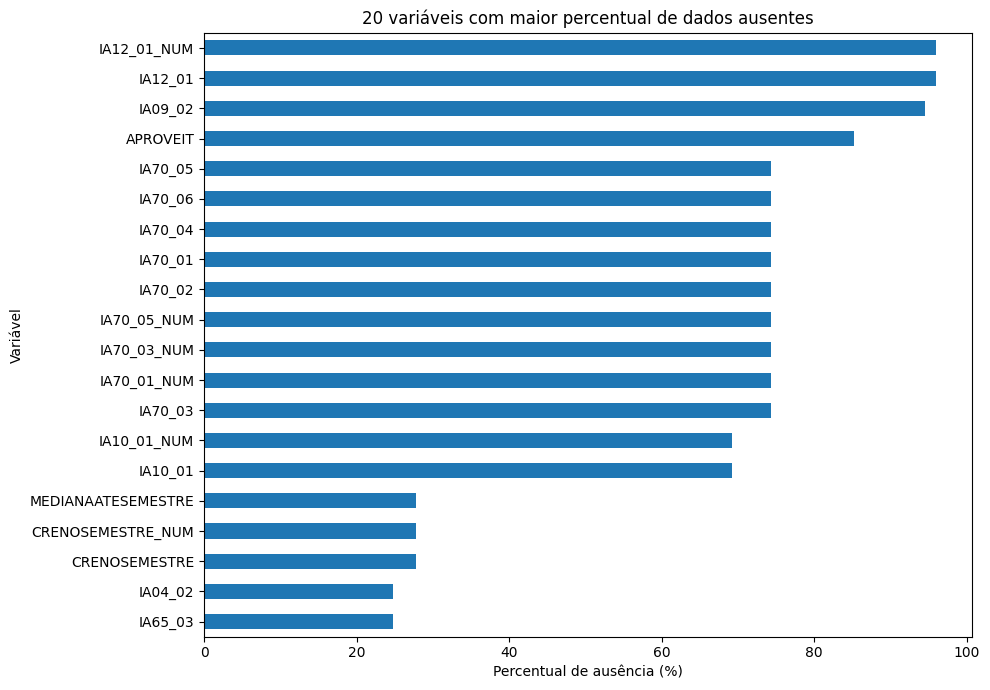

Registros com STATUSALUNO = 'Desconhecido': 19.2%


In [27]:
faltantes = (
    df.isna()
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

display(faltantes.head(20).to_frame("percentual_ausente"))

plt.figure(figsize=(10, 7))
faltantes.head(20).sort_values().plot(kind="barh")
plt.title("20 variáveis com maior percentual de dados ausentes")
plt.xlabel("Percentual de ausência (%)")
plt.ylabel("Variável")
plt.tight_layout()
plt.show()

# Além dos nulos "tradicionais", uma fatia relevante dos registros tem
# STATUSALUNO = "Desconhecido" — vale registrar isso como limitação também.
pct_desconhecido = (df["STATUSALUNO"] == "Desconhecido").mean() * 100
print(f"Registros com STATUSALUNO = 'Desconhecido': {pct_desconhecido:.1f}%")

## 22. O que a análise exploratória nos mostrou até aqui?

Depois de percorrer essas perguntas, conseguimos montar uma visão mais clara do problema que queremos investigar.

Primeiro, confirmamos que a base tem uma dimensão longitudinal que permite acompanhar estudantes em diferentes semestres. Depois identificamos os eventos institucionais de saída e vimos que eles precisam ser tratados com cuidado, principalmente porque existem estudantes que podem retornar ou apresentar mais de um episódio.

Na dimensão acadêmica, o resultado que mais chamou nossa atenção foi a diferença no CRE entre os grupos, especialmente no semestre anterior à primeira saída. A partir disso, ampliamos a análise para aprovação, reprovação, frequência e trancamento. Também verificamos dimensões financeiras e socioeconômicas, porque a trajetória de permanência não se resume ao desempenho acadêmico.

Ao mesmo tempo, encontramos uma limitação importante na própria definição inicial do desfecho: **314 estudantes estavam classificados como “Inativo” no sistema sem apresentar nenhum dos quatro eventos de saída utilizados inicialmente**. Isso mostra que ainda precisamos refinar a variável-alvo antes de aplicar os modelos.

Assim, a análise exploratória não encerra a investigação. Ela nos ajudou a decidir quais perguntas fazem sentido, quais variáveis merecem continuar na análise e quais cuidados precisamos tomar antes da etapa de aprendizado de máquina.

As principais questões que ficam para a próxima etapa são:

1. Quais características acadêmicas aparecem associadas aos eventos de saída?
2. A mudança observada no desempenho já aparece nos semestres anteriores à saída?
3. Frequência, aprovação, reprovação e progressão curricular apresentam padrões diferentes?
4. O histórico de trancamento aparece com maior frequência nas trajetórias de saída?
5. Existem diferenças relacionadas a bolsa, FIES, renda, patrimônio e escolaridade dos pais?
6. Esses padrões mudam entre cursos, turnos ou períodos?
7. Quantos eventos de saída representam uma saída definitiva e quantos são seguidos por retorno ou reingresso?
8. Como devemos definir a variável-alvo para representar corretamente o fenômeno que queremos estudar?
9. Quais variáveis permanecem relevantes quando analisadas em conjunto?

O objetivo da próxima etapa, portanto, não é procurar uma única variável que “explique” a evasão. Queremos verificar se diferentes dimensões da trajetória, analisadas em conjunto, ajudam a identificar padrões associados aos estudantes que apresentam eventos de saída.


# O que realmente precisamos levar para a pré-defesa

Como a apresentação terá cerca de seis minutos, não precisamos mostrar todos os gráficos produzidos no notebook. A ideia é selecionar aqueles que ajudam a contar a história da pesquisa.

A sequência que pensamos em apresentar é:

1. **Caracterização da base:** 59.059 registros, 7.615 estudantes e 35 semestres.
2. **Estrutura longitudinal:** mostrar que os estudantes aparecem em diferentes semestres.
3. **Situação dos estudantes ao final do período observado:** formados, cursando e estudantes com saída observada, desde que a classificação final seja validada.
4. **Eventos de saída:** quantidade e tipos de eventos registrados.
5. **Distribuição temporal:** em quais períodos os eventos aparecem.
6. **Trajetória acadêmica:** comparação do CRE e dos indicadores de aprovação/reprovação antes da saída.
7. **Frequência e trancamento:** verificar se aparecem diferenças nas trajetórias.
8. **Dimensões financeira e socioeconômica:** apresentar apenas os resultados que mostrarem diferenças ou padrões relevantes.
9. **Retorno e reingresso:** mostrar por que um evento de saída não pode ser tratado automaticamente como evasão definitiva.
10. **Qualidade dos dados e definição da variável-alvo:** destacar os 314 casos de “Inativo” que não foram capturados pelos quatro flags iniciais.
11. **Próxima etapa:** preparar a base e aplicar técnicas de aprendizado de máquina para analisar as variáveis conjuntamente.

A ideia é que os gráficos não apareçam como resultados isolados. Cada um deve responder a uma pergunta que surgiu durante a construção do trabalho.


## Referências utilizadas como apoio

As referências abaixo foram utilizadas para orientar as perguntas da análise e a interpretação dos resultados, e não para impor à base do Inatel um comportamento que veio de outra instituição.

- **TINTO, Vincent.** *Leaving College: Rethinking the Causes and Cures of Student Attrition*. University of Chicago Press, 1994. Utilizamos principalmente a perspectiva de permanência e saída como processos relacionados à trajetória do estudante.
- **TINTO, Vincent.** *Completing College: Rethinking Institutional Action*. University of Chicago Press, 2012. Utilizamos como complemento para discutir experiência acadêmica, envolvimento e condições relacionadas à permanência.
- **OLIVEIRA, R. S.; MEDEIROS, F. P. A.** Trabalho sobre predição de evasão com mineração de dados educacionais e autoavaliação institucional. Foi utilizado como referência metodológica complementar para a utilização de dados acadêmicos e técnicas de aprendizado de máquina.
- **BARBOSA et al.** *Previsão da Evasão Escolar através da Análise de Dados e Aprendizagem de Máquina: um estudo de caso*. Utilizado como referência de outro estudo de caso que trabalha com dados educacionais e aprendizado de máquina.
- **IBM — CRISP-DM.** Utilizada como referência para a organização das etapas de entendimento e preparação dos dados antes da modelagem.

A ideia central que orientou esta etapa foi simples: primeiro entender os dados e o fenômeno que estamos estudando; depois definir com cuidado o desfecho; e só então partir para a modelagem.
